# EDA: Indian Unicorn Startups

In [26]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = Path("data/raw/tracxn.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/raw/tracxn.csv")

# The Kaggle CSV contains a few Windows-1252 characters (for example, non-breaking spaces).
df = pd.read_csv(DATA_PATH, encoding="cp1252")
print(f"Loaded {DATA_PATH} with shape {df.shape}")


Loaded ../data/raw/tracxn.csv with shape (118, 19)


## 1. Dataset overview

In [27]:
overview = pd.DataFrame({
    "metric": ["rows", "columns", "unique companies", "duplicate rows", "duplicate company names"],
    "value": [len(df), df.shape[1], df["Company"].nunique(), df.duplicated().sum(), df["Company"].duplicated().sum()],
})
display(overview)
display(df.head(3))
display(df.dtypes.rename("dtype").to_frame())


,metric,value
0,rows,118
1,columns,19
2,unique companies,118
3,duplicate rows,0
4,duplicate company names,0


,Rank,Company,company_link,company_info,round_led_by,company_background,founded_year,location,country,stage,primary_sector,time_to_unicorn,top_investors_1,top_investors_2,annual_revenue,valuation,total_funding_till_date,employee_count,latest_funding_round
0,118,Juspay,https://tracxn.com/d/companies/juspay/__fDjQyo...,"Juspay joined the Unicorn Club on Apr 07, 2025...",Kedaara,Provider of a global payments operating system...,2012,Bengaluru,India,Series D,Payments,13 years 3 months,Wellington,Kedaara,"?348Cr as on Mar 31, 2024","?3,450Cr as on Jun 23, 2022",$88M,"1,015 as on Feb 28, 2025","Series D, Apr 07, 2025"
1,117,Money View,https://tracxn.com/d/companies/money-view/__NR...,"Money View joined the Unicorn Club on Sep 12, ...",Accel,Provider of digital financial services includi...,2014,Bengaluru,India,Series E,Alternative Lending,10 years 8 months,Accel,Nexus Venture Partners,"?1,390Cr as on Mar 31, 2024","?10,100Cr as on Sep 17, 2024",$220M,"709 as on Feb 28, 2025","Series E, Sep 12, 2024, $4.65M"
2,116,Ather Energy,https://tracxn.com/d/companies/ather-energy/__...,Ather Energy joined the Unicorn Club on Aug 13...,NIIF,Electric vehicle manufacturer offering scooter...,2013,Bengaluru,India,Public,Electric Vehicles,11 years 7 months,Herald Investment Management,GIC,"?1,790Cr as on Mar 31, 2024",$502M,NaN,"1,630 as on Mar 31, 2025","Series E, Aug 13, 2024, $71.5M"


,dtype
Rank,int64
Company,str
company_link,str
company_info,str
round_led_by,str
company_background,str
founded_year,int64
location,str
country,str
stage,str


## 2. Data quality checks

In [28]:
missing = (df.isna().sum().rename("missing_count").to_frame().assign(missing_percentage=lambda x: (x["missing_count"] / len(df) * 100).round(1)).sort_values("missing_count", ascending=False))
display(missing)

if df["Company"].duplicated().any():
    display(df[df["Company"].duplicated(keep=False)].sort_values("Company"))
else:
    print("No duplicate company names found.")


,missing_count,missing_percentage
round_led_by,47,39.8
total_funding_till_date,31,26.3
employee_count,15,12.7
valuation,2,1.7
top_investors_1,1,0.8
top_investors_2,1,0.8
Rank,0,0.0
company_link,0,0.0
Company,0,0.0
company_background,0,0.0


No duplicate company names found.


## 3. Normalize fields used by the chatbot

In [29]:
def clean_text(series):
    return series.fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

for column in ["Company", "location", "country", "stage", "primary_sector", "top_investors_1", "top_investors_2"]:
    if column in df:
        df[f"{column}_clean"] = clean_text(df[column])

df["location_clean"] = df["location_clean"].replace({"Bangalore": "Bengaluru", "bangalore": "Bengaluru"})
location_comparison = df[["location", "location_clean"]].value_counts(dropna=False).rename("count").reset_index()
display(location_comparison.head(20))


,location,location_clean,count
0,Bengaluru,Bengaluru,46
1,Gurugram,Gurugram,18
2,Mumbai,Mumbai,15
3,Delhi,Delhi,5
4,Pune,Pune,5
5,Chennai,Chennai,4
6,San Francisco,San Francisco,4
7,Noida,Noida,3
8,Singapore,Singapore,2
9,Bellevue,Bellevue,2


## 4. Category distributions


primary_sector_clean


,primary_sector_clean,company_count,percentage
0,Payments,11,9.3
1,Logistics Tech,7,5.9
2,Horizontal E-Commerce,6,5.1
3,Alternative Lending,5,4.2
4,Online Grocery,4,3.4
5,K-12 EdTech,4,3.4
6,Auto E-Commerce & Content,4,3.4
7,B2B E-Commerce,4,3.4
8,Banking Tech,3,2.5
9,Healthcare Booking Platforms,3,2.5



location_clean


,location_clean,company_count,percentage
0,Bengaluru,46,39.0
1,Gurugram,18,15.3
2,Mumbai,15,12.7
3,Delhi,5,4.2
4,Pune,5,4.2
5,Chennai,4,3.4
6,San Francisco,4,3.4
7,Noida,3,2.5
8,Singapore,2,1.7
9,Bellevue,2,1.7



stage_clean


,stage_clean,company_count,percentage
0,Series E,19,16.1
1,Series F,18,15.3
2,Series D,17,14.4
3,Public,14,11.9
4,Series C,13,11.0
5,Series G,9,7.6
6,Acquired,7,5.9
7,Series H,7,5.9
8,Series B,6,5.1
9,Series J,2,1.7


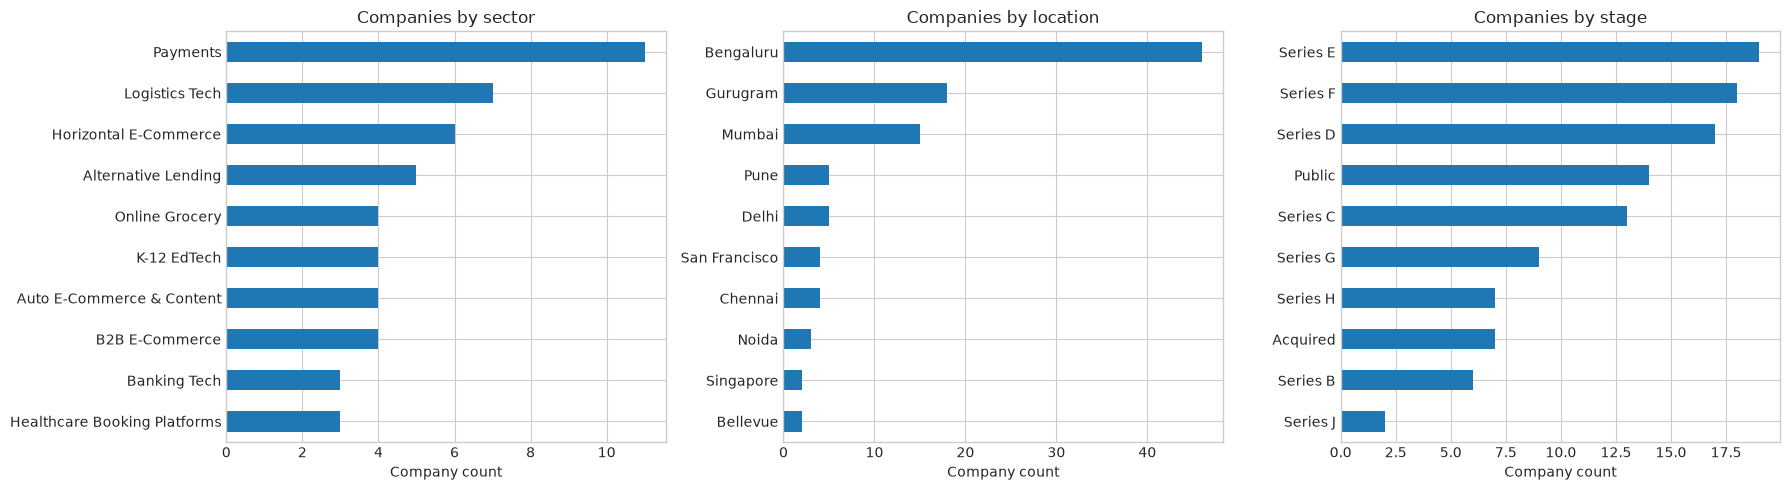

In [30]:
for column in ["primary_sector_clean", "location_clean", "stage_clean"]:
    summary = df[column].replace("", "Unknown").value_counts().rename_axis(column).reset_index(name="company_count")
    summary["percentage"] = (summary["company_count"] / len(df) * 100).round(1)
    print(f"\n{column}")
    display(summary.head(15))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column, title in zip(axes, ["primary_sector_clean", "location_clean", "stage_clean"], ["Companies by sector", "Companies by location", "Companies by stage"]):
    counts = df[column].replace("", "Unknown").value_counts().head(10).sort_values()
    counts.plot.barh(ax=ax, title=title)
    ax.set_xlabel("Company count")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


## 5. Numeric fields and financial values

Financial values contain currency symbols, commas, units, and embedded dates. The parser below extracts the first numeric value and converts common million/billion/crore units to an approximate USD-million scale where possible. These derived values are for exploration; the original strings remain the source text.

,count,mean,std,min,25%,50%,75%,max
annual_revenue_numeric,118.0,678.55,1280.73,0.37,47.19,172.2,757.8,8496.0
valuation_numeric,116.0,378653.09,2481687.46,13.00,731.50,1280.0,2730.0,22635000.0
total_funding_numeric,87.0,143442.62,1232032.35,51.10,251.00,393.0,762.5,11464000.0
employee_count_numeric,103.0,995632.56,3247839.91,4.00,744.50,4400.0,743000.0,24590000.0


,Company,valuation,valuation_numeric
104,Policybazaar,"22,635 as on Feb 28, 2025",22635000.0
101,BillDesk,"?11,400Cr as on Feb 15, 2019",11400000.0
31,LEAD School,"?9,070Cr as on Feb 09, 2024",9070000.0
113,Quikr,"$566M as on Feb 19, 2020",566000.0
116,Flipkart,"$36B as on May 25, 2024",36000.0
62,Blinkit,"$13B as on Apr 26, 2024",13000.0
80,PhonePe,"?1,04,000Cr as on May 31, 2023",12480.0
98,Dream11,"$8B as on Nov 26, 2021",8000.0
89,FirstCry,"6,895 as on Sep 30, 2024",6895.0
70,Groww,"$6.8B as on Mar 26, 2025",6800.0


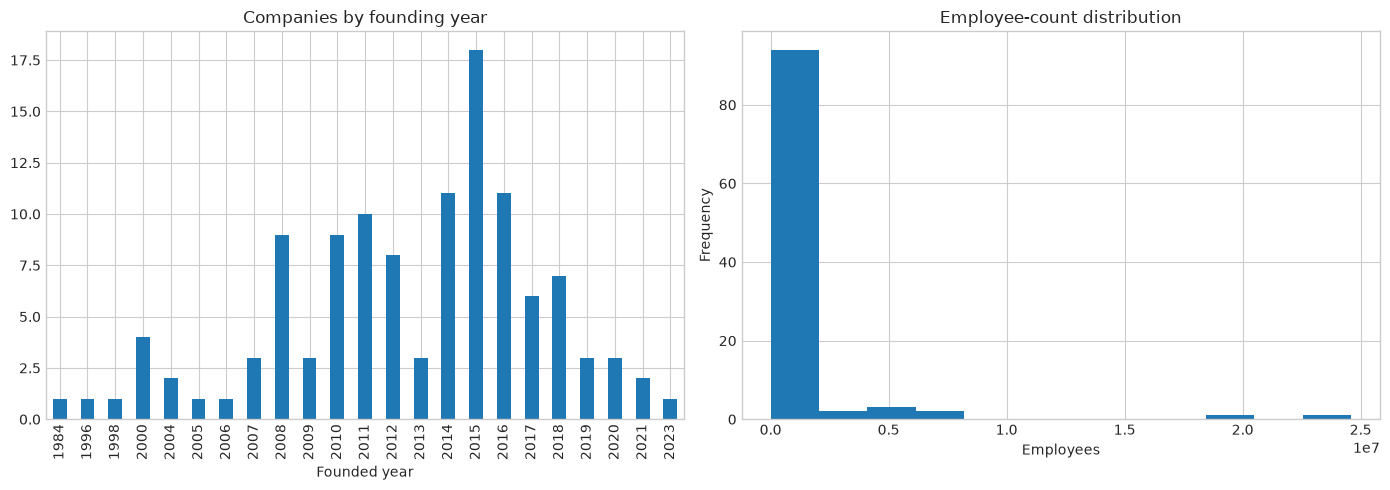

In [31]:
def parse_amount(value):
    if pd.isna(value) or str(value).strip() in {"", "?"}:
        return pd.NA
    text = str(value).replace(",", "").replace("?", "").strip()
    match = re.search(r"[-+]?\d+(?:\.\d+)?", text)
    if not match:
        return pd.NA
    amount = float(match.group())
    lower = text.lower()
    if "b" in lower or "billion" in lower:
        amount *= 1000
    elif "cr" in lower or "crore" in lower:
        amount *= 0.12
    return amount

for source, target in {"annual_revenue": "annual_revenue_numeric", "valuation": "valuation_numeric", "total_funding_till_date": "total_funding_numeric", "employee_count": "employee_count_numeric"}.items():
    if source in df:
        df[target] = pd.to_numeric(df[source].map(parse_amount), errors="coerce")

numeric_columns = [column for column in df.columns if column.endswith("_numeric")]
display(df[numeric_columns].describe().T.round(2))
if "valuation_numeric" in df:
    display(df[["Company", "valuation", "valuation_numeric"]].sort_values("valuation_numeric", ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["founded_year"].dropna().astype(int).value_counts().sort_index().plot.bar(ax=axes[0], title="Companies by founding year")
if "employee_count_numeric" in df:
    df["employee_count_numeric"].dropna().plot.hist(ax=axes[1], bins=12, title="Employee-count distribution")
axes[0].set_xlabel("Founded year")
axes[1].set_xlabel("Employees")
plt.tight_layout()
plt.show()


## 6. Text quality for retrieval

The company descriptions are likely to be used as retrieval context. Empty or unusually short descriptions should be handled explicitly by the chatbot.

,column,empty_count,median_length,short_count_<100_chars
0,company_info,0,119.5,47
1,company_background,0,388.0,0


,Company,company_background,company_background_length
104,Policybazaar,"Online platform for insurance buyers in India,...",115
60,Droom,AI-powered used vehicle dealer. Users can buy ...,157
73,Five Star Business Finance,Provider of consumer and business loans. It of...,162
3,Rapido,"Platform offering bike taxi, auto rickshaw, an...",165
74,Infra.Market,B2B platform offering building materials. The ...,165
56,upGrad,Online education platform offering professiona...,176
81,Cars24,App based platform for buying second-hand cars...,200
58,OfBusiness,Marketplace for trading multi-category industr...,205
19,Games24x7,Provider of online gaming platform offering sk...,238
110,ShopClues,Online marketplace offering multi-category pro...,243


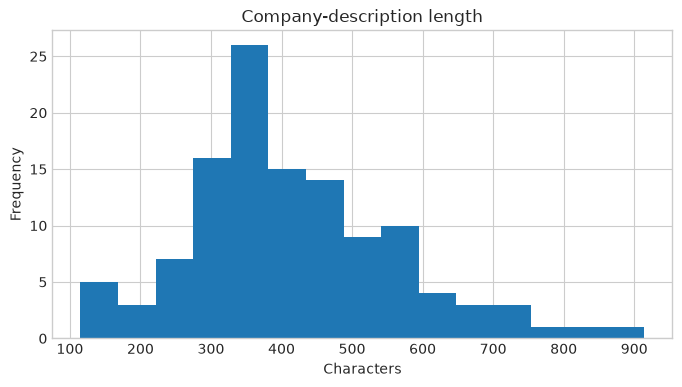

In [32]:
for column in ["company_info", "company_background"]:
    if column in df:
        df[f"{column}_length"] = clean_text(df[column]).str.len()

text_columns = [column for column in ["company_info", "company_background"] if column in df]
text_summary = pd.DataFrame({"column": text_columns, "empty_count": [df[column].fillna("").astype(str).str.strip().eq("").sum() for column in text_columns], "median_length": [df[f"{column}_length"].median() for column in text_columns], "short_count_<100_chars": [df[f"{column}_length"].lt(100).sum() for column in text_columns]})
display(text_summary)
if "company_background" in df:
    display(df[["Company", "company_background", "company_background_length"]].sort_values("company_background_length").head(10))
if "company_background_length" in df:
    df["company_background_length"].plot.hist(bins=15, figsize=(8, 4), title="Company-description length")
    plt.xlabel("Characters")
    plt.show()
